# 04 · H2: intervención en el núcleo, ajuste exclusivo del decodificador de máscaras

**Hipótesis H2 (registrada por el equipo en el E1).** Ajustar exclusivamente el decodificador, con ambos codificadores congelados, mejora el desempeño frente a SAM preentrenado bajo la misma estrategia de prompts.

**Control H2-c.** Sonda lineal 1×1 (257 parámetros) sobre el mismo embedding congelado, sin prompts.

El protocolo quedó fijado antes de entrenar (`docs/protocolo_preregistrado.md`, sección 3):

* Solo se entrenan los 4 058 340 parámetros del decodificador. El codificador de imagen (89.7 M) y el de prompts quedan congelados.
* Prompts automáticos de Otsu: aleatorios con semilla al entrenar y los deterministas de v2 al evaluar. Nunca se toman de la etiqueta.
* BCE + Dice, AdamW (decaimiento 0.01), lote 4, **12 épocas**, sin *early stopping*.
* La tasa de aprendizaje se elige en `train-dev` (20 % de train). Luego se entrenan las semillas 0, 1 y 2 en todo train y se evalúa en valid. `test` no se toca.

Gracias a la caché de embeddings, cada paso de entrenamiento solo ejecuta el decodificador. Eso hace viable el experimento incluso en CPU. La versión final se ejecutó en una GPU NVIDIA RTX 3070; los embeddings se habían calculado en CPU.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from safetensors.torch import save_file

from inf659sam import config, data, stats
from inf659sam.baseline import iou_components, normalize_band, otsu_masks
from inf659sam.cache import encode_and_cache, load_embedding, save_json
from inf659sam.decoder_ft import (decoder_state, load_decoder_state, load_training_set, probe_predict,
                                  train_decoder, train_probe)
from inf659sam.experiments import evaluate_chip, rows_for
from inf659sam.sam_utils import SamWrapper

config.setup_runtime(seed=0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9})
parts = json.loads((config.RESULTS_DIR / "particiones_usadas.json").read_text(encoding="utf-8"))
TRAIN, CORE, DEV, VALID = parts["train"], parts["train_core"], parts["train_dev"], parts["valid"]
print(f"train {len(TRAIN)} (core {len(CORE)} + dev {len(DEV)}) | valid {len(VALID)}")
sam = SamWrapper()
encode_and_cache(sam, TRAIN, rep="vh3", probe=True)
encode_and_cache(sam, VALID, rep="vh3", probe=True)
PRE = decoder_state(sam)
LOG = config.RESULTS_DIR / "H2_entrenamiento.log"
OUT = {"protocolo": {"epocas": 12, "lote": 4, "weight_decay": 0.01, "semillas": list(config.SEEDS),
                     "barrido_lr": [3e-5, 1e-4, 3e-4], "salida": "una mascara", "perdida": "BCE + Dice"}}


def eval_single(chips):
    """Evalua la salida de una mascara con el decodificador ACTUAL y los prompts deterministas de v2."""
    return [evaluate_chip(sam, c, rep="vh3", methods=("sam_single",))["sam_single"] for c in chips]

Entorno: {'seed': 0, 'torch_threads': 8}
train 250 (core 199 + dev 51) | valid 86


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights:  26%|██▌       | 81/314 [00:00<00:00, 780.38it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 1757.71it/s]

## 1. Barrido de tasa de aprendizaje en `train-dev` (semilla 0)

In [2]:
items_core = load_training_set(CORE)
sweep = []
load_decoder_state(sam, PRE)
base_dev = stats.aggregate(eval_single(DEV))["global_iou"]
for lr in OUT["protocolo"]["barrido_lr"]:
    load_decoder_state(sam, PRE)
    h = train_decoder(sam, items_core, seed=0, lr=lr, log_file=LOG, tag="-barrido")
    iou_dev = stats.aggregate(eval_single(DEV))["global_iou"]
    sweep.append({"lr": lr, "IoU_global_train_dev": iou_dev, "perdida_final": h["historial"][-1]["perdida_media"],
                  "minutos": h["minutos"], "historial": h["historial"]})
    print(f"lr={lr:g}: IoU train-dev {iou_dev:.4f} ({h['minutos']:.1f} min)")
best_lr = max(sweep, key=lambda s: s["IoU_global_train_dev"])["lr"]
OUT["barrido"] = {"preentrenado_train_dev": base_dev, "resultados": sweep, "lr_elegida": best_lr}
print(f"SAM preentrenado (una máscara) en train-dev: {base_dev:.4f} | lr elegida: {best_lr:g}")
del items_core

lr=3e-05: IoU train-dev 0.4394 (1.9 min)


lr=0.0001: IoU train-dev 0.3506 (2.0 min)


lr=0.0003: IoU train-dev 0.4329 (1.9 min)
SAM preentrenado (una máscara) en train-dev: 0.1390 | lr elegida: 3e-05


## 2. Entrenamiento con tres semillas en todo `train` y evaluación en `valid`

In [3]:
items = load_training_set(TRAIN)
load_decoder_state(sam, PRE)
pre_rows = eval_single(VALID)
ref = {c: evaluate_chip(sam, c, rep="vh3", methods=("otsu_opened", "sam_v2")) for c in VALID}
otsu_rows = [ref[c]["otsu_opened"] for c in VALID]
v2_rows = [ref[c]["sam_v2"] for c in VALID]
regions = [data.region_of(c) for c in VALID]
ft_rows, ft_hist = {}, {}
for seed in config.SEEDS:
    load_decoder_state(sam, PRE)
    h = train_decoder(sam, items, seed=seed, lr=best_lr, log_file=LOG)
    ft_rows[seed] = eval_single(VALID)
    ft_hist[seed] = h
    st = {k: v.detach().cpu().clone().contiguous() for k, v in sam.model.mask_decoder.state_dict().items()}
    (config.CACHE_DIR / "modelos").mkdir(parents=True, exist_ok=True)
    save_file(st, str(config.CACHE_DIR / "modelos" / f"mask_decoder_ft_seed{seed}.safetensors"))
    print(f"semilla {seed}: IoU global valid {stats.aggregate(ft_rows[seed])['global_iou']:.4f} ({h['minutos']:.1f} min)")
load_decoder_state(sam, PRE)

semilla 0: IoU global valid 0.4684 (2.5 min)


semilla 1: IoU global valid 0.4315 (2.4 min)


semilla 2: IoU global valid 0.3932 (2.5 min)


## 3. Control H2-c: sonda lineal sobre el embedding congelado

In [4]:
probe_rows, probe_hist = {}, {}
for seed in config.SEEDS:
    probe, h = train_probe(items, seed=seed, log_file=LOG)
    rows = []
    for c in VALID:
        lab = data.load_chip(c)["label"]
        pred = probe_predict(probe, load_embedding(c)["emb"])
        r = iou_components(pred, lab == 1, lab != -1)
        r["area_frac"] = float(pred[lab != -1].mean())
        rows.append(r)
    probe_rows[seed], probe_hist[seed] = rows, h
    print(f"sonda semilla {seed}: IoU global valid {stats.aggregate(rows)['global_iou']:.4f}")

sonda semilla 0: IoU global valid 0.0771


sonda semilla 1: IoU global valid 0.0740


sonda semilla 2: IoU global valid 0.0676


## 4. Resultado de H2 con incertidumbre

In [5]:
def summary(rows_by_seed):
    g = [stats.aggregate(r)["global_iou"] for r in rows_by_seed.values()]
    m = [stats.aggregate(r)["mean_chip_iou"] for r in rows_by_seed.values()]
    return stats.mean_std(g), stats.mean_std(m)


tab = []
for name, rows in (("Otsu con apertura", otsu_rows), ("SAM v2 (multimáscara)", v2_rows),
                   ("SAM preentrenado, una máscara", pre_rows)):
    a = stats.aggregate(rows)
    tab.append({"método": name, "IoU global": f"{a['global_iou']:.4f}", "IoU medio": f"{a['mean_chip_iou']:.4f}",
                "precisión": f"{a['precision']:.3f}", "sensibilidad": f"{a['recall']:.3f}"})
for name, rb in (("H2: decodificador ajustado (3 semillas)", ft_rows), ("H2-c: sonda lineal (3 semillas)", probe_rows)):
    g, m = summary(rb)
    pr = [stats.aggregate(r)["precision"] for r in rb.values()]
    rc = [stats.aggregate(r)["recall"] for r in rb.values()]
    tab.append({"método": name, "IoU global": f"{g['media']:.4f} ± {g['desv']:.4f}", "IoU medio": f"{m['media']:.4f} ± {m['desv']:.4f}",
                "precisión": f"{np.mean(pr):.3f}", "sensibilidad": f"{np.mean(rc):.3f}"})
df_h2 = pd.DataFrame(tab).set_index("método")

tests = {}
for seed in config.SEEDS:
    tests[f"FT_s{seed}_vs_preentrenado"] = stats.paired_bootstrap(pre_rows, ft_rows[seed], n_boot=5000)
    tests[f"FT_s{seed}_vs_otsu"] = stats.paired_bootstrap(otsu_rows, ft_rows[seed], n_boot=5000)
    tests[f"FT_s{seed}_vs_otsu_region"] = stats.paired_bootstrap(otsu_rows, ft_rows[seed], groups=regions, n_boot=5000)
    tests[f"FT_s{seed}_vs_sonda_s{seed}"] = stats.paired_bootstrap(probe_rows[seed], ft_rows[seed], n_boot=5000)
    tests[f"wilcoxon_FT_s{seed}_vs_otsu"] = stats.wilcoxon_paired([r["iou"] for r in otsu_rows], [r["iou"] for r in ft_rows[seed]])
    tests[f"wilcoxon_FT_s{seed}_vs_preentrenado"] = stats.wilcoxon_paired([r["iou"] for r in pre_rows], [r["iou"] for r in ft_rows[seed]])
for k, v in tests.items():
    if k.startswith("wilcoxon"):
        print(f"{k}: mejor en {v['b_mejor']}/{v['n']} chips, p = {v.get('p_valor')}")
    else:
        gi = v["global_iou"]
        print(f"{k}: Δ IoU global {gi['diff_b_menos_a']:+.4f}  IC95 [{gi['ic95'][0]:+.4f}, {gi['ic95'][1]:+.4f}]")
OUT.update({"tabla": tab, "pruebas": tests,
            "por_chip": {"chips": VALID, "otsu": otsu_rows, "sam_v2": v2_rows, "preentrenado_una": pre_rows,
                         "ft": {str(k): v for k, v in ft_rows.items()}, "sonda": {str(k): v for k, v in probe_rows.items()}},
            "historial_ft": {str(k): v for k, v in ft_hist.items()}, "historial_sonda": {str(k): v for k, v in probe_hist.items()}})
save_json(OUT, config.RESULTS_DIR / "H2_resultados.json")
df_h2

FT_s0_vs_preentrenado: Δ IoU global +0.3300  IC95 [+0.2444, +0.4131]
FT_s0_vs_otsu: Δ IoU global +0.2128  IC95 [+0.1366, +0.2890]
FT_s0_vs_otsu_region: Δ IoU global +0.2128  IC95 [+0.1347, +0.3018]
FT_s0_vs_sonda_s0: Δ IoU global +0.3914  IC95 [+0.2869, +0.4839]
wilcoxon_FT_s0_vs_otsu: mejor en 57/86 chips, p = 1.803533187481562e-05
wilcoxon_FT_s0_vs_preentrenado: mejor en 61/86 chips, p = 4.195497664804893e-09
FT_s1_vs_preentrenado: Δ IoU global +0.2931  IC95 [+0.1715, +0.4154]
FT_s1_vs_otsu: Δ IoU global +0.1759  IC95 [+0.0634, +0.2925]
FT_s1_vs_otsu_region: Δ IoU global +0.1759  IC95 [+0.0305, +0.3045]
FT_s1_vs_sonda_s1: Δ IoU global +0.3576  IC95 [+0.2450, +0.4700]
wilcoxon_FT_s1_vs_otsu: mejor en 51/86 chips, p = 0.002374720406222831
wilcoxon_FT_s1_vs_preentrenado: mejor en 56/86 chips, p = 1.6757173209430702e-06
FT_s2_vs_preentrenado: Δ IoU global +0.2548  IC95 [+0.1616, +0.3423]
FT_s2_vs_otsu: Δ IoU global +0.1376  IC95 [+0.0371, +0.2261]
FT_s2_vs_otsu_region: Δ IoU global +0.13

,IoU global,IoU medio,precisión,sensibilidad
método,,,,
Otsu con apertura,0.2556,0.2525,0.282,0.731
SAM v2 (multimáscara),0.1146,0.1458,0.118,0.793
"SAM preentrenado, una máscara",0.1385,0.1667,0.150,0.648
H2: decodificador ajustado (3 semillas),0.4311 ± 0.0376,0.3130 ± 0.0147,0.665,0.555
H2-c: sonda lineal (3 semillas),0.0729 ± 0.0048,0.1151 ± 0.0036,0.675,0.076


## 5. Curvas de entrenamiento y resultados por región

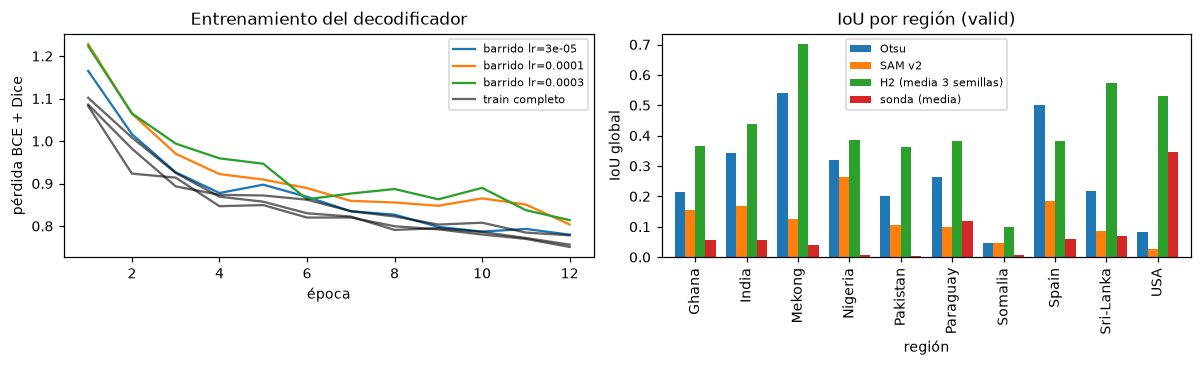

,chips,Otsu,SAM v2,H2 (media 3 semillas),sonda (media)
región,,,,,
Ghana,8,0.215,0.156,0.364,0.056
India,14,0.342,0.169,0.439,0.055
Mekong,6,0.542,0.126,0.700,0.038
Nigeria,4,0.320,0.263,0.385,0.006
Pakistan,6,0.202,0.106,0.362,0.005
Paraguay,14,0.264,0.099,0.384,0.120
Somalia,5,0.045,0.045,0.098,0.005
Spain,6,0.501,0.186,0.381,0.060
Sri-Lanka,9,0.216,0.087,0.575,0.071


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for s in sweep:
    axes[0].plot([e["epoca"] for e in s["historial"]], [e["perdida_media"] for e in s["historial"]], label=f"barrido lr={s['lr']:g}")
for seed, h in ft_hist.items():
    axes[0].plot([e["epoca"] for e in h["historial"]], [e["perdida_media"] for e in h["historial"]], "k-", alpha=0.6,
                 label="train completo" if seed == 0 else None)
axes[0].set_xlabel("época")
axes[0].set_ylabel("pérdida BCE + Dice")
axes[0].set_title("Entrenamiento del decodificador")
axes[0].legend(fontsize=7)
reg_rows = []
for reg in sorted(set(regions)):
    idx = [i for i, g in enumerate(regions) if g == reg]
    row = {"región": reg, "chips": len(idx),
           "Otsu": stats.aggregate([otsu_rows[i] for i in idx])["global_iou"],
           "SAM v2": stats.aggregate([v2_rows[i] for i in idx])["global_iou"],
           "H2 (media 3 semillas)": np.mean([stats.aggregate([ft_rows[s][i] for i in idx])["global_iou"] for s in config.SEEDS]),
           "sonda (media)": np.mean([stats.aggregate([probe_rows[s][i] for i in idx])["global_iou"] for s in config.SEEDS])}
    reg_rows.append(row)
df_reg = pd.DataFrame(reg_rows).set_index("región")
df_reg[["Otsu", "SAM v2", "H2 (media 3 semillas)", "sonda (media)"]].plot.bar(ax=axes[1], width=0.8)
axes[1].set_ylabel("IoU global")
axes[1].set_title("IoU por región (valid)")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "H2_curvas_y_regiones.png")
plt.show()
OUT["por_region"] = reg_rows
save_json(OUT, config.RESULTS_DIR / "H2_resultados.json")
df_reg.round(3)

## 6. Análisis de fallas (Fase C): ¿dónde sigue fallando el decodificador ajustado?

In [7]:
ft_mean = np.array([np.nanmean([ft_rows[s][i]["iou"] if ft_rows[s][i]["iou"] is not None else np.nan for s in config.SEEDS])
                    for i in range(len(VALID))])
otsu_i = np.array([r["iou"] if r["iou"] is not None else np.nan for r in otsu_rows])
gt_frac = []
for c in VALID:
    lab = data.load_chip(c)["label"]
    gt_frac.append(float((lab == 1)[lab != -1].mean()))
gt_frac = np.array(gt_frac)
fails = pd.DataFrame({"chip": VALID, "región": regions, "agua_real_pct": 100 * gt_frac, "IoU_Otsu": otsu_i, "IoU_H2": ft_mean,
                      "FP_H2_s0": [r["fp"] for r in ft_rows[0]], "FN_H2_s0": [r["fn"] for r in ft_rows[0]]})
fails["H2_menos_Otsu"] = fails["IoU_H2"] - fails["IoU_Otsu"]
print("Correlación de Spearman entre fracción de agua real e IoU de H2:",
      round(pd.Series(gt_frac).corr(pd.Series(ft_mean), method="spearman"), 3))
print("Chips con menos de 1 % de agua real:", int((gt_frac < 0.01).sum()), "| IoU H2 medio en ellos:",
      round(np.nanmean(ft_mean[gt_frac < 0.01]), 3), "| en el resto:", round(np.nanmean(ft_mean[gt_frac >= 0.01]), 3))
OUT["fallas"] = fails.to_dict(orient="records")
save_json(OUT, config.RESULTS_DIR / "H2_resultados.json")
fails.sort_values("IoU_H2").head(10).round(3)

Correlación de Spearman entre fracción de agua real e IoU de H2: 0.713
Chips con menos de 1 % de agua real: 28 | IoU H2 medio en ellos: 0.092 | en el resto: 0.42


,chip,región,agua_real_pct,IoU_Otsu,IoU_H2,FP_H2_s0,FN_H2_s0,H2_menos_Otsu
3,Ghana_132163,Ghana,0.000,0.0,0.0,276,0,0.0
2,Ghana_142312,Ghana,0.000,0.0,0.0,801,0,0.0
5,Ghana_124834,Ghana,0.000,0.0,0.0,2935,0,0.0
13,India_244057,India,0.003,0.0,0.0,13026,5,-0.0
42,Paraguay_284928,Paraguay,0.000,0.0,0.0,48300,0,0.0
47,Paraguay_7894,Paraguay,0.000,0.0,0.0,506,0,0.0
36,Pakistan_336228,Pakistan,0.000,0.0,0.0,10308,0,0.0
34,Pakistan_210595,Pakistan,0.000,0.0,0.0,10080,0,0.0
54,Somalia_61368,Somalia,0.000,0.0,0.0,496,0,0.0
53,Somalia_256539,Somalia,0.010,0.0,0.0,4963,23,-0.0


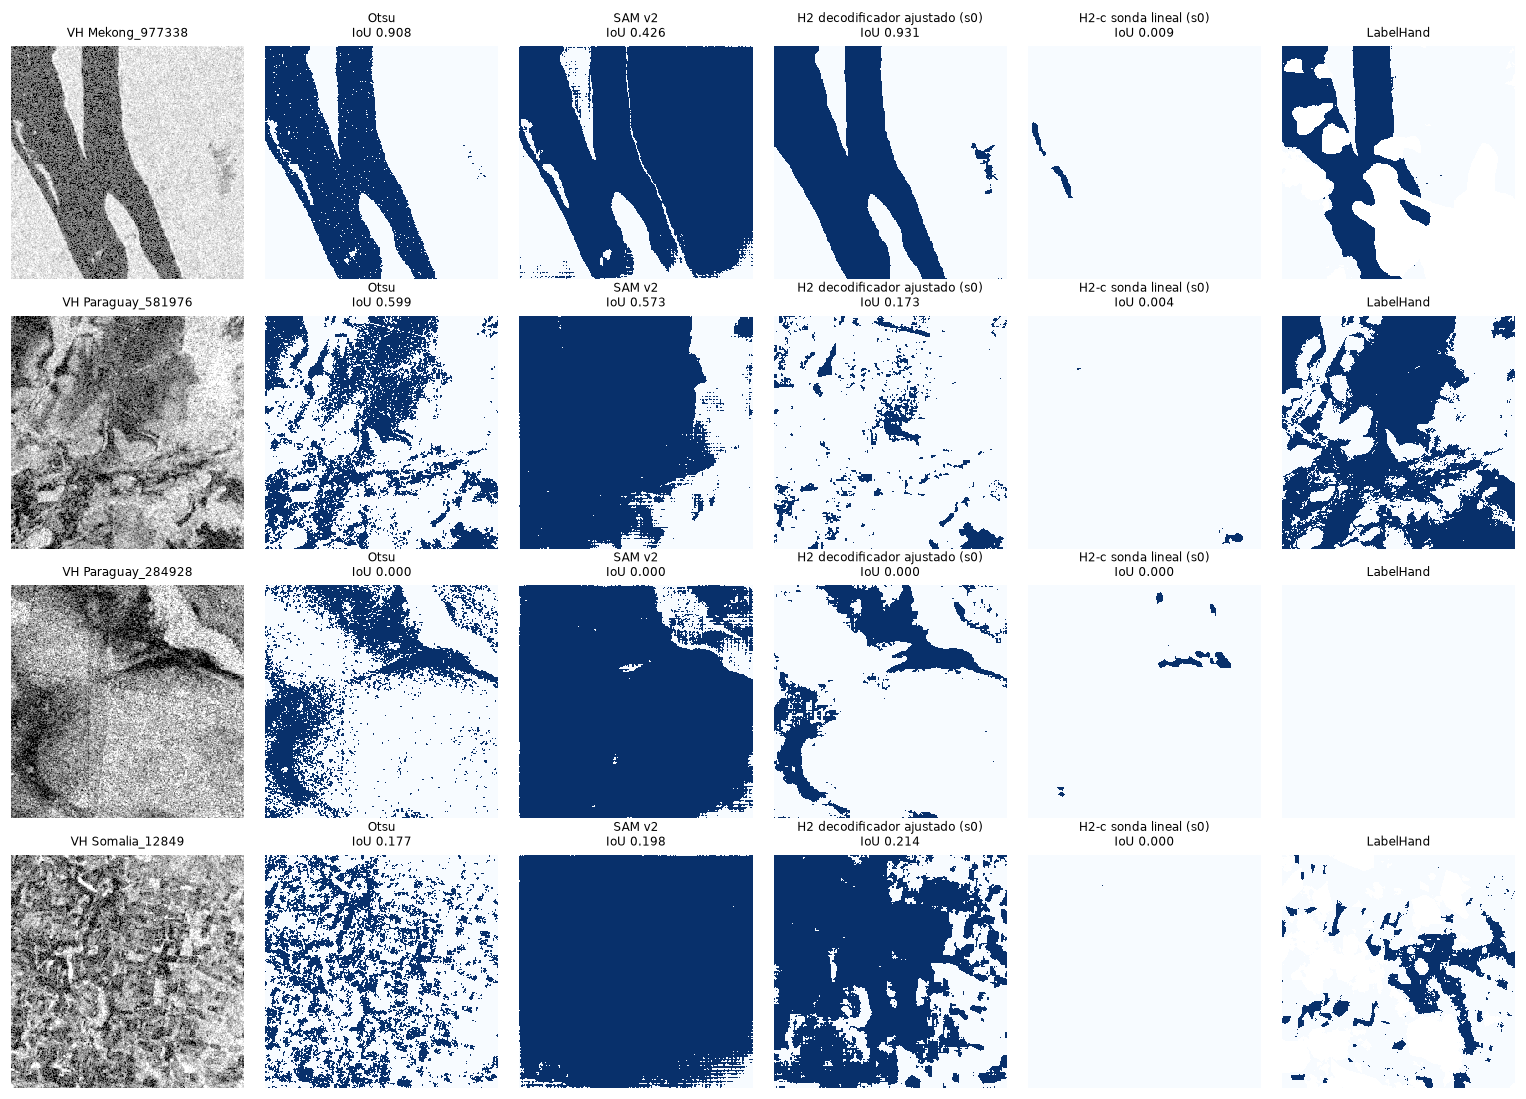

In [8]:
from safetensors.torch import load_file

from inf659sam.baseline import auto_prompts

show = [VALID[i] for i in np.argsort(-np.nan_to_num(ft_mean, nan=-1))[[0, len(VALID) // 2, -1]]]
show = list(dict.fromkeys(show + ["Somalia_12849"]))
probe0, _ = train_probe(items, seed=0)
load_decoder_state(sam, PRE)
fig, axes = plt.subplots(len(show), 6, figsize=(14, 2.5 * len(show)))
ft0 = load_file(str(config.CACHE_DIR / "modelos" / "mask_decoder_ft_seed0.safetensors"))
for r, c in enumerate(show):
    d = data.load_chip(c)
    lab = d["label"]
    om = otsu_masks(d["vv"], d["vh"])
    load_decoder_state(sam, PRE)
    pts, lbs, k = auto_prompts(om["opened"], om["sensor_valid"])
    emb = load_embedding(c)
    m_v2 = sam.decode(emb["emb"], pts, lbs, emb["original_sizes"], emb["reshaped_input_sizes"]) if k else None
    sam.model.mask_decoder.load_state_dict(ft0)
    m_ft = sam.decode(emb["emb"], pts, lbs, emb["original_sizes"], emb["reshaped_input_sizes"], multimask=False) if k else None
    load_decoder_state(sam, PRE)
    panels = [("VH " + c, normalize_band(d["vh"]), "gray"), ("Otsu", om["opened"], "Blues"),
              ("SAM v2", m_v2["masks"][int(np.argmax(m_v2["scores"]))] if m_v2 else np.zeros_like(lab), "Blues"),
              ("H2 decodificador ajustado (s0)", m_ft["masks"][0] if m_ft else np.zeros_like(lab), "Blues"),
              ("H2-c sonda lineal (s0)", probe_predict(probe0, emb["emb"]), "Blues"),
              ("LabelHand", np.where(lab != -1, (lab == 1).astype(float), np.nan), "Blues")]
    for a, (t, im, cm) in zip(axes[r], panels):
        a.imshow(im, cmap=cm, interpolation="nearest")
        if t not in ("LabelHand",) and not t.startswith("VH"):
            iou = iou_components(im.astype(bool), lab == 1, lab != -1)["iou"]
            t = f"{t}\nIoU {iou:.3f}" if iou is not None else t
        a.set_title(t, fontsize=8)
        a.axis("off")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "H2_cualitativo.png")
plt.show()